In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

In [ ]:
!pip install transformers datasets evaluate accelerate

In [ ]:
!pip install torch

In [1]:
import os
import re
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
warnings.filterwarnings("ignore")

In [2]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
sentiment_columns = [
    "target",
    "id",
    "date",
    "flag",
    "user",
    "text"
]
sentiment_df = pd.read_csv(
    "Training.csv",
    encoding="latin-1",
    header=None,
    names=sentiment_columns
)
sentiment_df.head()

,target,id,date,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


In [4]:
sentiment_df = pd.read_csv(
    "Training.csv",
    encoding="latin-1",
    header=None,
    names=sentiment_columns
)

In [5]:
sentiment_df.shape

(1600000, 6)

In [6]:
sentiment_df.columns

Index(['target', 'id', 'date', 'flag', 'user', 'text'], dtype='object')

In [7]:
sentiment_df.isnull().sum()

target    0
id        0
date      0
flag      0
user      0
text      0
dtype: int64

In [8]:
sentiment_df["target"].value_counts()

target
0    800000
4    800000
Name: count, dtype: int64

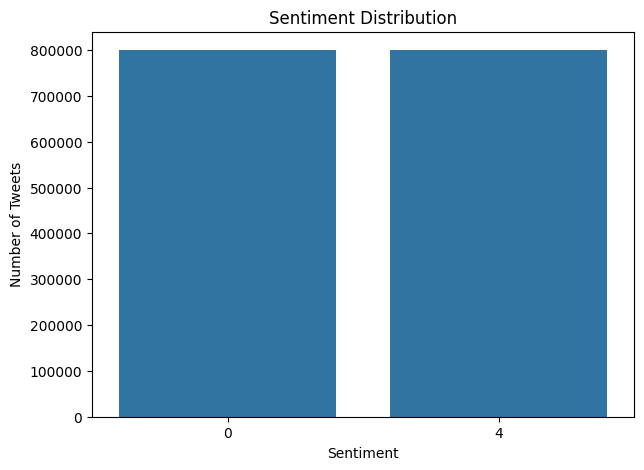

In [9]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=sentiment_df,
    x="target"
)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

In [10]:
sentiment_df["sentiment"] = sentiment_df["target"].map({
    0: "Negative",
    4: "Positive"
})

In [11]:
sentiment_df[["text", "sentiment"]].head()

,text,sentiment
0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",Negative
1,is upset that he can't update his Facebook by ...,Negative
2,@Kenichan I dived many times for the ball. Man...,Negative
3,my whole body feels itchy and like its on fire,Negative
4,"@nationwideclass no, it's not behaving at all....",Negative


In [12]:
sentiment_df = sentiment_df[
    ["text", "sentiment"]
]
sentiment_df.head()

,text,sentiment
0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",Negative
1,is upset that he can't update his Facebook by ...,Negative
2,@Kenichan I dived many times for the ball. Man...,Negative
3,my whole body feels itchy and like its on fire,Negative
4,"@nationwideclass no, it's not behaving at all....",Negative


In [13]:
sentiment_df = sentiment_df.drop_duplicates(
    subset=["text"]
)
sentiment_df.shape

(1581466, 2)

In [14]:
stop_words = set(stopwords.words("english"))

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    text = str(text)

    # lowercase
    text = text.lower()

    # remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # remove mentions
    text = re.sub(r"@\w+", "", text)

    # remove hashtag symbol
    text = re.sub(r"#", "", text)

    # remove HTML
    text = re.sub(r"<.*?>", "", text)

    # remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # remove numbers
    text = re.sub(r"\d+", "", text)

    # tokenize
    tokens = word_tokenize(text)

    # stopword removal + lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
        and len(word) > 2
    ]

    return " ".join(tokens)

In [15]:
sample = """
I absolutely LOVE this movie!!!
Check https://example.com
It is amazing #awesome @user
"""

print(clean_text(sample))

absolutely love movie check amazing awesome


In [16]:
sentiment_sample = sentiment_df.groupby(
    "sentiment",
    group_keys=False
).sample(
    n=150000,
    random_state=42
)

sentiment_sample.shape

(300000, 2)

In [17]:
sentiment_sample["clean_text"] = sentiment_sample["text"].apply(
    clean_text
)

In [18]:
sentiment_sample.head()

,text,sentiment,clean_text
797724,my ipod can stop this restore to factory setti...,Negative,ipod stop restore factory setting nonsense whe...
723288,headache!!!! waaaaaaaa,Negative,headache waaaaaaaa
413887,I'm going to bed and sleeping in tomorrow morn...,Negative,going bed sleeping tomorrow morning hope one d...
580748,"it's the same old song, but with a different m...",Negative,old song different meaning since youve gone
539577,@weezyREBEL i didnt finish watching it the web...,Negative,didnt finish watching website kept making slow...


In [19]:
sentiment_sample = sentiment_sample[
    sentiment_sample["clean_text"].str.strip() != ""
]
sentiment_sample.shape

(298361, 3)

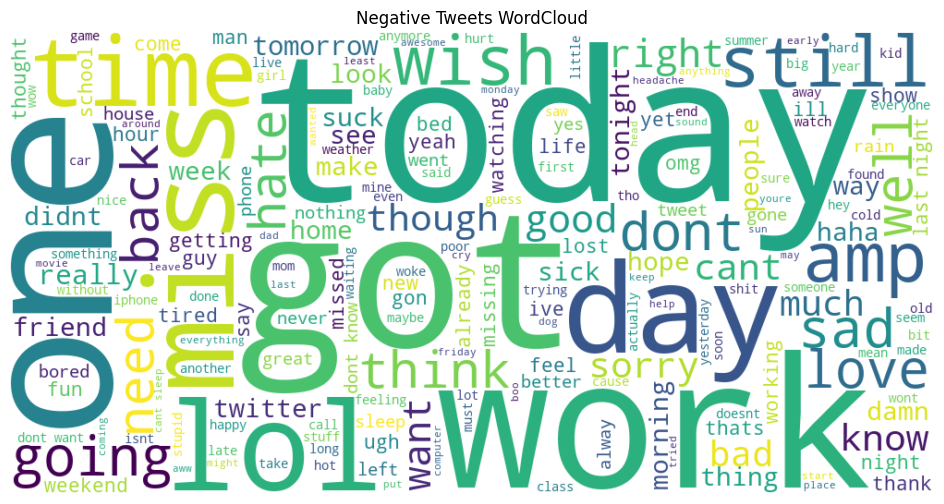

In [20]:
negative_text = " ".join(
    sentiment_sample[
        sentiment_sample["sentiment"] == "Negative"
    ]["clean_text"]
)

wordcloud_negative = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(12,6))

plt.imshow(
    wordcloud_negative,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Negative Tweets WordCloud")

plt.show()

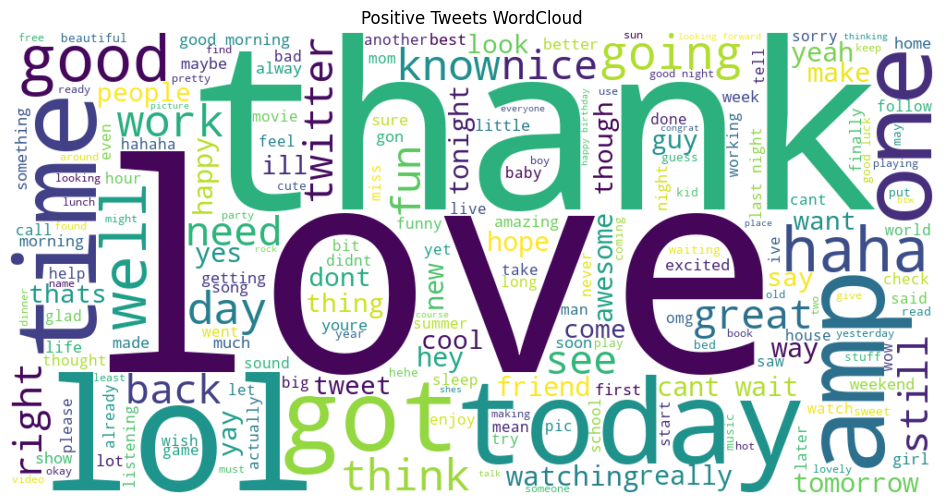

In [21]:
positive_text = " ".join(
    sentiment_sample[
        sentiment_sample["sentiment"] == "Positive"
    ]["clean_text"]
)

wordcloud_positive = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(12,6))

plt.imshow(
    wordcloud_positive,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Positive Tweets WordCloud")

plt.show()

In [22]:
X = sentiment_sample["clean_text"]

y = sentiment_sample["sentiment"]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 238688
Testing: 59673


In [24]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [25]:
X_train_tfidf.shape

(238688, 50000)

In [26]:
lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [27]:
y_pred = lr_model.predict(
    X_test_tfidf
)

In [28]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.7819114172238701


In [29]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

    Negative       0.79      0.76      0.78     29848
    Positive       0.77      0.80      0.79     29825

    accuracy                           0.78     59673
   macro avg       0.78      0.78      0.78     59673
weighted avg       0.78      0.78      0.78     59673



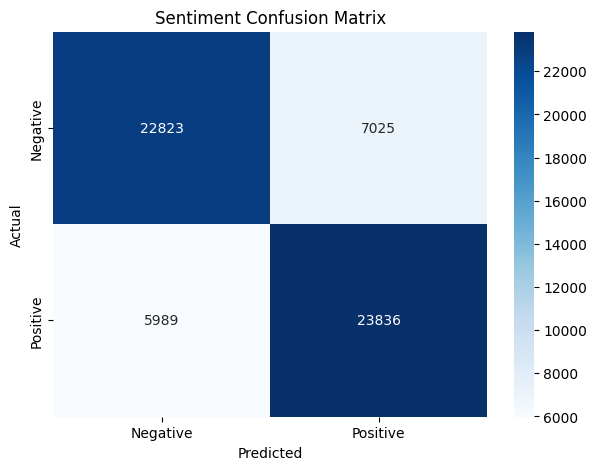

In [30]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Sentiment Confusion Matrix")

plt.show()

In [31]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from datasets import Dataset

In [32]:
bert_df = sentiment_sample.sample(
    n=20000,
    random_state=42
).copy()

In [33]:
bert_df["label"] = bert_df["sentiment"].map({
    "Negative": 0,
    "Positive": 1
})

In [34]:
bert_df = bert_df[
    ["clean_text", "label"]
]

bert_df.head()

,clean_text,label
1039556,trippin awesome chianti buzz,1
831678,going make hot chocolate visit favourite music...,1
845411,yayyyy see may cnd stay lannndannn,1
875427,youre telling,1
1430061,going drive movie,1


In [35]:
bert_train, bert_test = train_test_split(
    bert_df,
    test_size=0.2,
    random_state=42,
    stratify=bert_df["label"]
)

In [36]:
train_dataset = Dataset.from_pandas(
    bert_train.reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    bert_test.reset_index(drop=True)
)

In [37]:
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

In [38]:
def tokenize_function(examples):

    return tokenizer(
        examples["clean_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [39]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

In [40]:
tokenized_train = tokenized_train.remove_columns(
    ["clean_text"]
)

tokenized_test = tokenized_test.remove_columns(
    ["clean_text"]
)

In [41]:
tokenized_train.set_format("torch")

tokenized_test.set_format("torch")

In [42]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [43]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "f1": f1_score(
            labels,
            predictions
        ),
        "precision": precision_score(
            labels,
            predictions
        ),
        "recall": recall_score(
            labels,
            predictions
        )
    }

In [44]:
training_args = TrainingArguments(
    output_dir="./bert_sentiment_model",

    eval_strategy="steps",
    eval_steps=50,

    learning_rate=3e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    max_steps=100,

    logging_steps=20,

    save_strategy="no",
    report_to="none"
)

In [ ]:
training_args = TrainingArguments(
    output_dir="./bert_sentiment_model",
    eval_strategy="steps",
    eval_steps=100,
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    max_steps=500,
    logging_steps=50,
    save_strategy="no",
    report_to="none"
)

In [ ]:
training_args = TrainingArguments(
    output_dir="./bert_sentiment_model",

    eval_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,

    per_device_eval_batch_size=8,

    num_train_epochs=1,

    weight_decay=0.01,

    logging_steps=100,

    save_strategy="epoch",

    load_best_model_at_end=True,

    report_to="none"
)

In [45]:
trainer = Trainer(
    model=bert_model,

    args=training_args,

    train_dataset=tokenized_train,

    eval_dataset=tokenized_test,

    processing_class=tokenizer,

    compute_metrics=compute_metrics
)

In [46]:
trainer.train()

Step,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
50,0.640414,0.644246,0.635750,0.556739,0.708204,0.458647
100,0.616215,0.619881,0.671000,0.657648,0.683613,0.633584


TrainOutput(global_step=100, training_loss=0.6464063739776611, metrics={'train_runtime': 5721.9382, 'train_samples_per_second': 0.14, 'train_steps_per_second': 0.017, 'total_flos': 52622211072000.0, 'train_loss': 0.6464063739776611, 'epoch': 0.05})

In [47]:
bert_results = trainer.evaluate()

bert_results

Training Loss,Validation Loss,Step,Accuracy,F1,Precision,Recall
0.616215,0.619881,100,0.671000,0.657648,0.683613,0.633584


{'eval_loss': 0.6198810338973999,
 'eval_accuracy': 0.671,
 'eval_f1': 0.6576482830385015,
 'eval_precision': 0.6836127636560303,
 'eval_recall': 0.6335839598997494}

In [48]:
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "BERT"
    ],

    "Accuracy": [
        accuracy,
        bert_results["eval_accuracy"]
    ],

    "F1 Score": [
        f1_score(
            y_test,
            y_pred,
            average="binary",
            pos_label="Positive"
        ),
        bert_results["eval_f1"]
    ]
})

comparison

,Model,Accuracy,F1 Score
0,TF-IDF + Logistic Regression,0.781911,0.785552
1,BERT,0.671000,0.657648


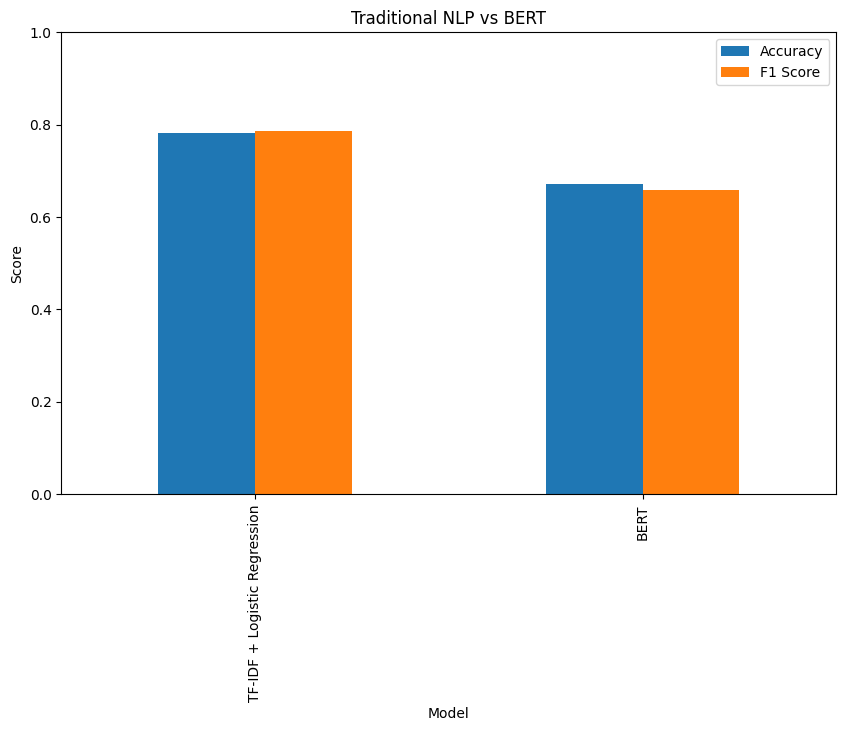

In [49]:
comparison.plot(
    x="Model",
    y=["Accuracy", "F1 Score"],
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Traditional NLP vs BERT"
)

plt.ylabel("Score")

plt.ylim(0,1)

plt.show()

In [50]:
def predict_sentiment(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    outputs = bert_model(**inputs)

    probabilities = (
        outputs.logits
        .softmax(dim=1)
    )

    prediction = torch.argmax(
        probabilities,
        dim=1
    ).item()

    if prediction == 0:
        sentiment = "Negative"
    else:
        sentiment = "Positive"

    confidence = probabilities[
        0, prediction
    ].item()

    return sentiment, confidence

In [51]:
import torch

In [52]:
text = "I absolutely love this project. It is amazing!"

predict_sentiment(text)

('Positive', 0.7159877419471741)

In [53]:
### Emotion Analysis

In [55]:
emotion_df = pd.read_csv(
    "Emotion.csv"
)
emotion_df.head()

,Unnamed: 0,text,label
0,0,i just feel really helpless and heavy hearted,4
1,1,ive enjoyed being able to slouch about relax a...,0
2,2,i gave up my internship with the dmrg and am f...,4
3,3,i dont know i feel so lost,0
4,4,i am a kindergarten teacher and i am thoroughl...,4


In [58]:
emotion_df = pd.read_csv(
    "Emotion.csv"
)

In [59]:
emotion_df.columns

Index(['Unnamed: 0', 'text', 'label'], dtype='object')

In [60]:
emotion_df.shape

(416809, 3)

In [61]:
emotion_df.head()

,Unnamed: 0,text,label
0,0,i just feel really helpless and heavy hearted,4
1,1,ive enjoyed being able to slouch about relax a...,0
2,2,i gave up my internship with the dmrg and am f...,4
3,3,i dont know i feel so lost,0
4,4,i am a kindergarten teacher and i am thoroughl...,4


In [62]:
emotion_df["label"].value_counts()

label
1    141067
0    121187
3     57317
4     47712
2     34554
5     14972
Name: count, dtype: int64

In [63]:
emotion_mapping = {
    0: "Sadness",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise"
}

In [64]:
emotion_df["emotion"] = emotion_df["label"].map(
    emotion_mapping
)

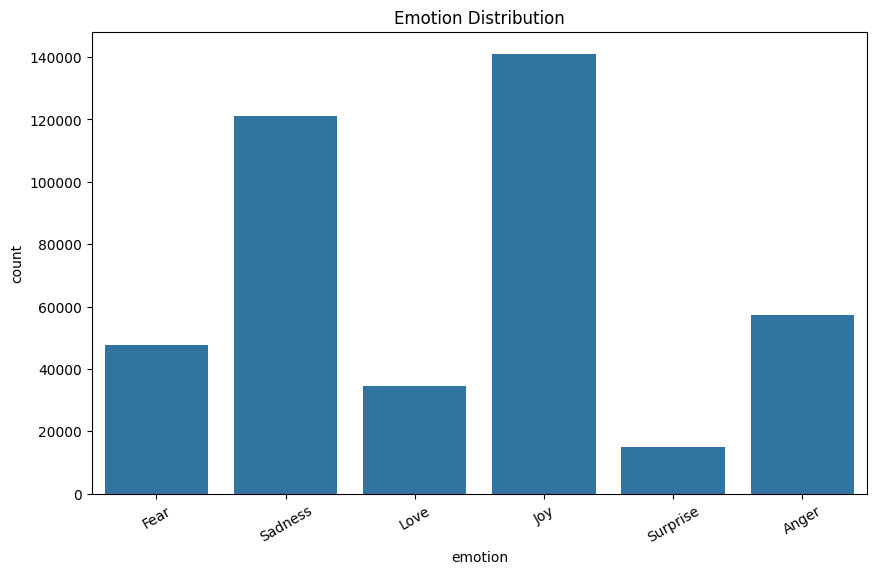

In [65]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=emotion_df,
    x="emotion"
)

plt.title(
    "Emotion Distribution"
)

plt.xticks(rotation=30)

plt.show()

In [66]:
emotion_df["clean_text"] = emotion_df["text"].apply(
    clean_text
)

In [67]:
emotion_df = emotion_df.dropna(
    subset=["clean_text", "emotion"]
)

emotion_df = emotion_df[
    emotion_df["clean_text"].str.strip() != ""
]

In [68]:
emotion_X = emotion_df["clean_text"]

emotion_y = emotion_df["emotion"]

In [69]:
emotion_X_train, emotion_X_test, emotion_y_train, emotion_y_test = train_test_split(
    emotion_X,
    emotion_y,
    test_size=0.2,
    random_state=42,
    stratify=emotion_y
)

In [70]:
emotion_tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95
)

emotion_X_train_tfidf = emotion_tfidf.fit_transform(
    emotion_X_train
)

emotion_X_test_tfidf = emotion_tfidf.transform(
    emotion_X_test
)

In [71]:
emotion_model = LogisticRegression(
    max_iter=1000
)

emotion_model.fit(
    emotion_X_train_tfidf,
    emotion_y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [72]:
emotion_pred = emotion_model.predict(
    emotion_X_test_tfidf
)

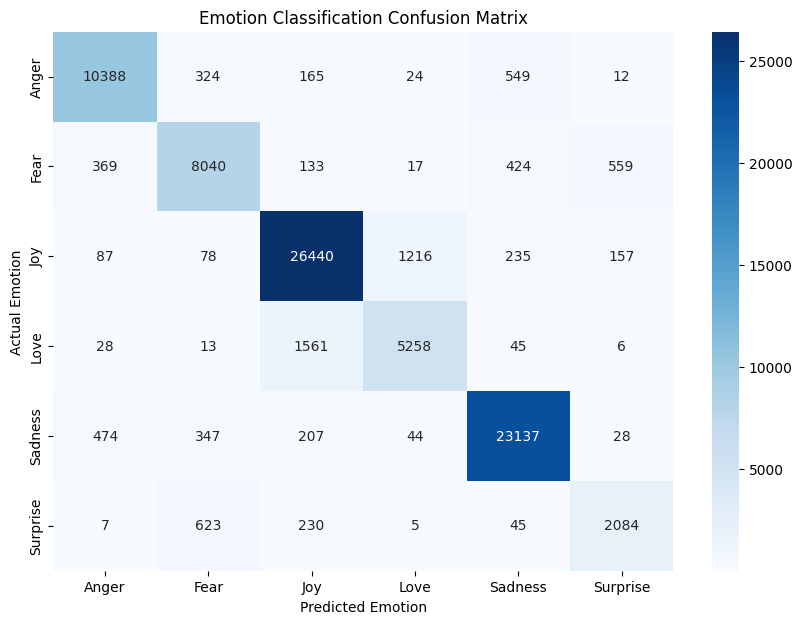

In [73]:
emotion_cm = confusion_matrix(
    emotion_y_test,
    emotion_pred,
    labels=emotion_model.classes_
)

plt.figure(figsize=(10,7))

sns.heatmap(
    emotion_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_model.classes_,
    yticklabels=emotion_model.classes_
)

plt.xlabel("Predicted Emotion")

plt.ylabel("Actual Emotion")

plt.title(
    "Emotion Classification Confusion Matrix"
)

plt.show()

In [74]:
def predict_emotion(text):

    cleaned = clean_text(text)

    vector = emotion_tfidf.transform(
        [cleaned]
    )

    prediction = emotion_model.predict(
        vector
    )[0]

    probabilities = emotion_model.predict_proba(
        vector
    )[0]

    confidence = max(probabilities)

    return prediction, confidence

In [75]:
predict_emotion(
    "I am extremely happy today because I got my dream job!"
)

('Joy', np.float64(0.7126831969546497))

In [76]:
predict_emotion(
    "I am scared about what will happen tomorrow."
)

('Fear', np.float64(0.9897758488088729))

In [77]:
def analyze_text(text):

    sentiment, sentiment_confidence = predict_sentiment(
        text
    )

    emotion, emotion_confidence = predict_emotion(
        text
    )

    result = {
        "Text": text,
        "Sentiment": sentiment,
        "Sentiment Confidence": round(
            sentiment_confidence, 4
        ),
        "Emotion": emotion,
        "Emotion Confidence": round(
            emotion_confidence, 4
        )
    }

    return pd.DataFrame([result])

In [78]:
analyze_text(
    "I am so happy! I finally got selected for my dream job."
)

,Text,Sentiment,Sentiment Confidence,Emotion,Emotion Confidence
0,I am so happy! I finally got selected for my d...,Positive,0.7098,Joy,0.8229


In [79]:
texts = [
    "I love this product, it is amazing!",
    "This is the worst experience ever.",
    "I am scared about the result.",
    "I am extremely happy today.",
    "I hate this service.",
    "I miss my old friends."
]

results = []

for text in texts:

    sentiment, sentiment_confidence = predict_sentiment(text)

    emotion, emotion_confidence = predict_emotion(text)

    results.append({
        "Text": text,
        "Sentiment": sentiment,
        "Sentiment Confidence": sentiment_confidence,
        "Emotion": emotion,
        "Emotion Confidence": emotion_confidence
    })

results_df = pd.DataFrame(results)

results_df

,Text,Sentiment,Sentiment Confidence,Emotion,Emotion Confidence
0,"I love this product, it is amazing!",Positive,0.706990,Surprise,0.714096
1,This is the worst experience ever.,Positive,0.606829,Joy,0.435825
2,I am scared about the result.,Positive,0.537711,Fear,0.997648
3,I am extremely happy today.,Positive,0.707599,Joy,0.819082
4,I hate this service.,Negative,0.518775,Sadness,0.343190
5,I miss my old friends.,Positive,0.630934,Joy,0.347483


In [80]:
results_df.to_csv(
    "social_media_analysis_results.csv",
    index=False
)

In [83]:
import joblib

joblib.dump(
    tfidf,
    "sentiment_tfidf.pkl"
)

joblib.dump(
    lr_model,
    "sentiment_model.pkl"
)

joblib.dump(
    emotion_tfidf,
    "emotion_tfidf.pkl"
)

joblib.dump(
    emotion_model,
    "emotion_model.pkl"
)

['emotion_model.pkl']